# Facial Expression Recognition Using a Convolutional Neural Network (CNN) with PyTorch

**Latihan untuk pemula · Google Colab · CNN dibuat dari awal**

Tujuan: mempelajari alur **gambar → tensor → CNN → prediksi kelas ekspresi**.
Penjelasan menggunakan bahasa Indonesia; kode dan nama hasil menggunakan bahasa Inggris.
Notebook ini belum dilatih. Angka akurasi hanya akan muncul setelah kamu menjalankannya.

Dataset: [Human Face Emotions — Samith Sachidanandan, Kaggle](https://www.kaggle.com/datasets/samithsachidanandan/human-face-emotions).
ZIP yang diperiksa berisi 59.099 file: Angry 10.148, Fear 9.732, Happy 18.439,
Sad 12.553, dan Suprise 8.227. Nama folder **`Suprise`** dipertahankan saat membaca data;
nama yang ditampilkan diperbaiki menjadi **`Surprise`**. Filemu tidak memiliki pembagian train/validation/test.

## Sebelum mulai
1. Upload **`archive (1).zip`** ke **My Drive** di Google Drive. Tidak perlu mengekstraknya di Drive.
2. Di Colab, pilih **Runtime → Change runtime type → GPU** (misalnya T4, bila tersedia).
3. Jalankan sel berurutan dengan tombol ▶ di kiri. Baca penjelasannya sebelum menjalankan sel berikutnya.
4. Pada bagian 2, sesuaikan `ZIP_PATH` dengan lokasi ZIP di Drive.

Data akan diekstrak ke penyimpanan sementara Colab supaya pembacaan gambar lebih cepat.
Hasil disimpan di **MyDrive/fer_cnn_outputs/<waktu_run>/** agar bertahan setelah runtime berakhir.
Ketersediaan GPU dan lama sesi Colab bervariasi. [Colab FAQ](https://research.google.com/colaboratory/faq.html)

**Batas latihan:** model memprediksi label ekspresi pada gambar. Evaluasi ini tidak mengukur diagnosis depresi
atau memastikan perasaan seseorang. Tidak ada ID orang yang andal; hasil split gambar bukan evaluasi orang baru.

## 1. Siapkan library
**PyTorch** membangun dan melatih CNN; **torchvision** mengubah gambar menjadi tensor;
**scikit-learn** membantu pembagian data dan evaluasi. Sel berikut hanya memasang paket yang belum ada.

In [2]:
import importlib.util
import subprocess
import sys

packages = {'torch': 'torch', 'torchvision': 'torchvision', 'sklearn': 'scikit-learn',
            'pandas': 'pandas', 'numpy': 'numpy', 'matplotlib': 'matplotlib',
            'PIL': 'pillow', 'tqdm': 'tqdm'}
missing = [package for module, package in packages.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *missing])

import hashlib
import json
import random
import shutil
import time
import warnings
import zipfile
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import math
import PIL
from PIL import Image, ImageOps
import sklearn
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix, ConfusionMatrixDisplay
import torch
import torchvision
from torch import nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm
from IPython.display import display

print('PyTorch:', torch.__version__)
print('GPU available:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('GPU:', torch.cuda.get_device_name(0))
else:
    print('CPU selected. Training works, but may take much longer; you can select a GPU runtime.')

PyTorch: 2.11.0+cpu
GPU available: False
CPU selected. Training works, but may take much longer; you can select a GPU runtime.


## 2. Hubungkan Google Drive dan pilih konfigurasi
Izinkan Colab mengakses Drive-mu ketika diminta. `ZIP_PATH` adalah **lokasi file**, bukan tautan berbagi Drive.
Contoh: ZIP di folder `datasets` berarti `/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip`.

- **Batch size 64:** model belajar dari 64 gambar per langkah.
- **Epoch 50:** maksimal lima putaran seluruh data latihan untuk percobaan pertama.
- **Learning rate 0.001:** ukuran langkah pembaruan bobot model.
- **Seed 42:** membantu mengulangi pembagian data. Hasil GPU tidak dijamin identik di semua perangkat.

Untuk latihan awal, biarkan konfigurasi model berikut tetap. Belajar mengubah satu pengaturan setelah run pertama selesai.

In [3]:
from google.colab import drive
drive.mount('/content/drive')

ZIP_PATH = Path('/content/drive/MyDrive/FacialExpression-Dataset/archive (1).zip')
OUTPUT_ROOT = Path('/content/drive/MyDrive/fer_cnn_outputs')

SEED = 42
IMAGE_SIZE = 64
BATCH_SIZE = 64
EPOCHS = 50
LEARNING_RATE = 3e-4 # Update Learning Rate
PATIENCE = 5
USE_CLASS_WEIGHTS = True
USE_AUGMENTATION = True
NUM_WORKERS = 0
CLASS_FOLDERS = ['Angry', 'Fear', 'Happy', 'Sad', 'Suprise']
CLASS_NAMES = ['Angry', 'Fear', 'Happy', 'Sad', 'Surprise']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
FOLDER_TO_LABEL = dict(zip(CLASS_FOLDERS, CLASS_NAMES))

assert ZIP_PATH.is_file(), f'ZIP not found: {ZIP_PATH}. Check its location in Google Drive.'
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)
torch.backends.cudnn.benchmark = False
torch.backends.cudnn.deterministic = True
DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

RUN_NAME = "cnn_experiment_v3"
RUN_DIR = OUTPUT_ROOT / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

print("Results folder:", RUN_DIR)
print('Results will be saved to:', RUN_DIR)

Mounted at /content/drive
Results folder: /content/drive/MyDrive/fer_cnn_outputs/cnn_experiment_v3
Results will be saved to: /content/drive/MyDrive/fer_cnn_outputs/cnn_experiment_v3


## 3. Ekstrak ZIP ke penyimpanan lokal Colab
Hash SHA-256 mengidentifikasi isi ZIP untuk dokumentasi. Folder ekstraksi menggunakan hash tersebut,
sehingga file dari dataset berbeda tidak tercampur. Jalankan hingga progress bar selesai.

In [4]:
def hash_file(path):
    digest = hashlib.sha256()
    with open(path, 'rb') as handle:
        for block in iter(lambda: handle.read(8 * 1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

archive_sha256 = hash_file(ZIP_PATH)
EXTRACT_DIR = Path('/content/fer_data') / archive_sha256[:16]
EXTRACT_DIR.mkdir(parents=True, exist_ok=True)
marker = EXTRACT_DIR / '.extraction_complete'
if not marker.exists():
    with zipfile.ZipFile(ZIP_PATH) as archive:
        entries = archive.infolist()
        required_bytes = sum(entry.file_size for entry in entries)
        assert shutil.disk_usage(EXTRACT_DIR).free > required_bytes + 1024**3, 'Not enough free runtime storage.'
        for entry in tqdm(entries, desc='Extracting'):
            relative = PurePosixPath(entry.filename)
            if relative.is_absolute() or '..' in relative.parts or '\\' in entry.filename:
                raise ValueError(f'Unsafe ZIP path: {entry.filename}')
            target = (EXTRACT_DIR / entry.filename).resolve()
            if not target.is_relative_to(EXTRACT_DIR.resolve()):
                raise ValueError(f'ZIP path outside destination: {entry.filename}')
            archive.extract(entry, EXTRACT_DIR)
    marker.write_text(archive_sha256)

candidates = [EXTRACT_DIR] + sorted(p for p in EXTRACT_DIR.rglob('Data') if p.is_dir())
candidates = [p for p in candidates if all((p / folder).is_dir() for folder in CLASS_FOLDERS)]
assert len(candidates) == 1, f'Expected one Data folder with {CLASS_FOLDERS}; found {candidates}'
DATA_DIR = candidates[0]
print('Data folder:', DATA_DIR)
print('ZIP SHA-256:', archive_sha256)

config = dict(seed=SEED, image_size=IMAGE_SIZE, batch_size=BATCH_SIZE, epochs=EPOCHS,
              learning_rate=LEARNING_RATE, patience=PATIENCE, use_class_weights=USE_CLASS_WEIGHTS,
              use_augmentation=USE_AUGMENTATION, class_names=CLASS_NAMES, folder_to_label=FOLDER_TO_LABEL,
              split_ratios=[0.70, 0.15, 0.15], archive_sha256=archive_sha256,
              archive_filename=ZIP_PATH.name, device=str(DEVICE))
(RUN_DIR / 'config.json').write_text(json.dumps(config, indent=2))
versions = {'python': sys.version, 'torch': str(torch.__version__), 'torchvision': torchvision.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'pillow': PIL.__version__,
            'sklearn': sklearn.__version__}
(RUN_DIR / 'environment_versions.json').write_text(json.dumps(versions, indent=2))

Extracting:   0%|          | 0/59099 [00:00<?, ?it/s]

Data folder: /content/fer_data/4524c810ef395c1a/Data
ZIP SHA-256: 4524c810ef395c1a0ab237da31fa117b9aee3a71ebf42c3d1e7f006d8e62027f


209

## 4. Periksa kualitas data sebelum membaginya
Kita mencoba membuka setiap gambar dan membuat hash dari **piksel RGB asli setelah orientasi EXIF diterapkan**.
Ukuran gambar ikut dihitung dalam hash. Gambar dengan piksel identik dianggap duplikat walaupun nama filenya berbeda.

- Gambar yang tidak dapat dibuka dicatat dan dilewati.
- Untuk duplikat dengan label sama, kita mempertahankan satu gambar.
- Jika piksel identik mempunyai label berbeda, seluruh kelompok tersebut dikeluarkan dan dicatat untuk ditinjau.

Ini mencegah duplikat persis masuk ke latihan dan pengujian sekaligus. Gambar yang hanya *mirip* masih mungkin ada;
hash persis tidak mendeteksi semua variasi crop, kompresi, atau orang yang sama. Pemeriksaan ini bisa memerlukan beberapa menit.

In [5]:
image_extensions = {'.png', '.jpg', '.jpeg', '.bmp', '.webp'}
paths = sorted(p for folder in CLASS_FOLDERS for p in (DATA_DIR / folder).rglob('*')
               if p.is_file() and p.suffix.lower() in image_extensions)
assert paths, 'No image files found.'
records, invalid = [], []
for path in tqdm(paths, desc='Checking images and exact duplicates'):
    folder = path.relative_to(DATA_DIR).parts[0]
    try:
        with warnings.catch_warnings():
            warnings.simplefilter('error', Image.DecompressionBombWarning)
            with Image.open(path) as original:
                original.load()
                original_width, original_height, mode = *original.size, original.mode
                image = ImageOps.exif_transpose(original).convert('RGB')
                digest = hashlib.sha256(str(image.size).encode() + b'|' + image.tobytes()).hexdigest()
        records.append({'path': path.relative_to(DATA_DIR).as_posix(),
                        'folder': folder,
                        'label': FOLDER_TO_LABEL[folder],
                        'width': original_width,
                        'height': original_height,
                        'mode': mode,
                        'pixel_sha256': digest})
    except Exception as error:
        invalid.append({'path': path.relative_to(DATA_DIR).as_posix(), 'error': str(error)})

manifest = pd.DataFrame(records)
assert len(manifest), 'No readable images remain.'
label_counts_per_hash = manifest.groupby('pixel_sha256')['label'].nunique()
conflict_hashes = set(label_counts_per_hash[label_counts_per_hash > 1].index)
conflicts = manifest[manifest.pixel_sha256.isin(conflict_hashes)].copy()
consistent = manifest[~manifest.pixel_sha256.isin(conflict_hashes)].copy()
clean = consistent.sort_values('path').drop_duplicates('pixel_sha256').reset_index(drop=True)
clean['target'] = clean.label.map(CLASS_TO_INDEX).astype(int)

manifest.to_csv(RUN_DIR / 'audit_manifest.csv', index=False)
pd.DataFrame(invalid, columns=['path', 'error']).to_csv(RUN_DIR / 'invalid_images.csv', index=False)
conflicts.to_csv(RUN_DIR / 'conflicting_labels.csv', index=False)
clean.to_csv(RUN_DIR / 'clean_manifest.csv', index=False)
audit_summary = {'input_images': len(paths), 'readable_images': len(manifest), 'invalid_images': len(invalid),
                 'conflicting_label_groups': len(conflict_hashes), 'conflicting_label_images': len(conflicts),
                 'same_label_duplicates_removed': len(consistent) - len(clean), 'retained_images': len(clean)}
(RUN_DIR / 'audit_summary.json').write_text(json.dumps(audit_summary, indent=2))
print(json.dumps(audit_summary, indent=2))

counts = pd.DataFrame({'original_readable': manifest.label.value_counts(),
                       'after_cleaning': clean.label.value_counts()}).reindex(CLASS_NAMES).fillna(0).astype(int)
display(counts)
assert (counts.after_cleaning >= 10).all(), 'Too few samples in one or more classes for stratified splitting.'

Checking images and exact duplicates:   0%|          | 0/59099 [00:00<?, ?it/s]

{
  "input_images": 59099,
  "readable_images": 59099,
  "invalid_images": 0,
  "conflicting_label_groups": 49,
  "conflicting_label_images": 262,
  "same_label_duplicates_removed": 30019,
  "retained_images": 28818
}


,original_readable,after_cleaning
label,,
Angry,10148,4959
Fear,9732,4822
Happy,18439,9255
Sad,12553,6310
Surprise,8227,3472


,images,percentage
label,,
Angry,4959,17.21
Fear,4822,16.73
Happy,9255,32.12
Sad,6310,21.90
Surprise,3472,12.05


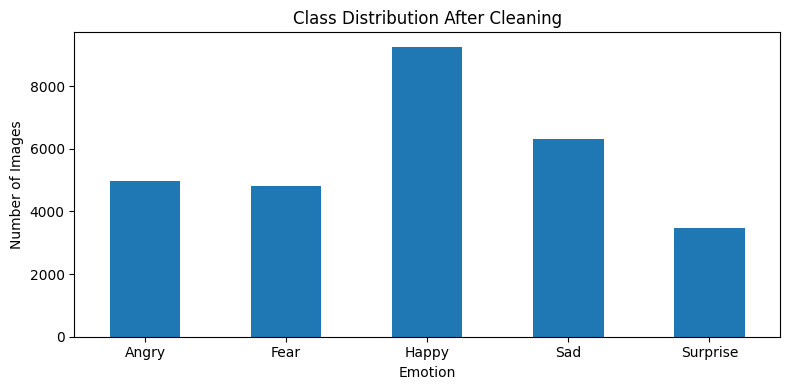

Image dimension statistics:


,width,height
count,28818.00,28818.00
mean,113.67,112.29
std,470.68,463.68
min,48.00,48.00
25%,48.00,48.00
50%,48.00,48.00
75%,48.00,48.00
max,8957.00,8184.00


Images smaller than 48 px in either dimension: 0


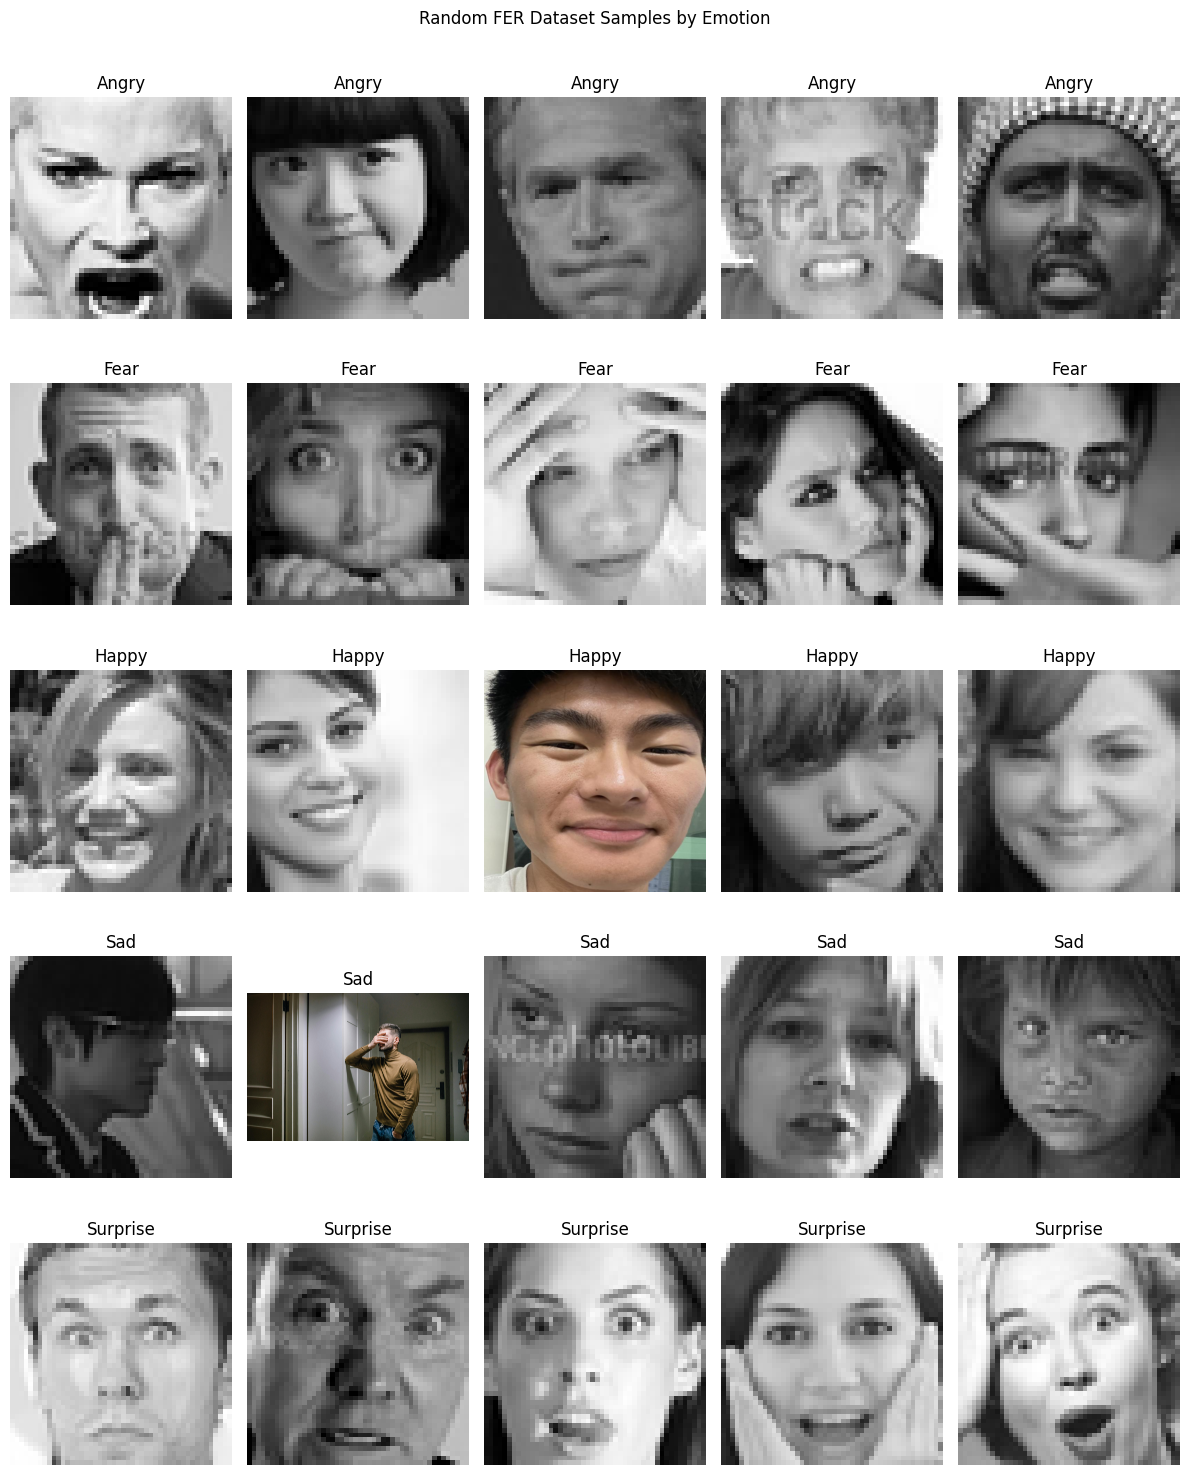

In [6]:
# 1. Inspect class distribution
class_counts = clean["label"].value_counts().reindex(CLASS_NAMES, fill_value=0)

display(pd.DataFrame({
    "images": class_counts,
    "percentage": (class_counts / len(clean) * 100).round(2)
}))

ax = class_counts.plot(kind="bar", figsize=(8, 4))
ax.set_title("Class Distribution After Cleaning")
ax.set_xlabel("Emotion")
ax.set_ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# 2. Inspect image dimensions
print("Image dimension statistics:")
display(
    clean[["width", "height"]]
    .describe()
    .round(2)
)

small_images = clean[
    (clean["width"] < 48) | (clean["height"] < 48)
]

print("Images smaller than 48 px in either dimension:",
      len(small_images))

# 3. Visually inspect random samples from each class
fig, axes = plt.subplots(
    len(CLASS_NAMES), 5,
    figsize=(12, 3 * len(CLASS_NAMES))
)

for row, emotion in enumerate(CLASS_NAMES):
    samples = clean[clean["label"] == emotion].sample(
        n=min(5, class_counts[emotion]),
        random_state=SEED
    )

    for col, (_, sample) in enumerate(samples.iterrows()):
        path = DATA_DIR / sample["path"]

        with Image.open(path) as img:
            img = ImageOps.exif_transpose(img).convert("RGB")
            axes[row, col].imshow(img)

        axes[row, col].set_title(emotion)
        axes[row, col].axis("off")

    for col in range(len(samples), 5):
        axes[row, col].axis("off")

plt.suptitle("Random FER Dataset Samples by Emotion", y=1.002)
plt.tight_layout()
plt.show()


## 5. Lihat contoh dan distribusi kelas
Judul gambar di bawah merupakan **label dari dataset**, bukan hasil prediksi.
Perhatikan apakah semua contoh benar-benar menunjukkan wajah dan apakah labelnya masuk akal.
Jika ada label meragukan, catat sebagai keterbatasan; pemeriksaan otomatis tidak menjamin semua label benar.

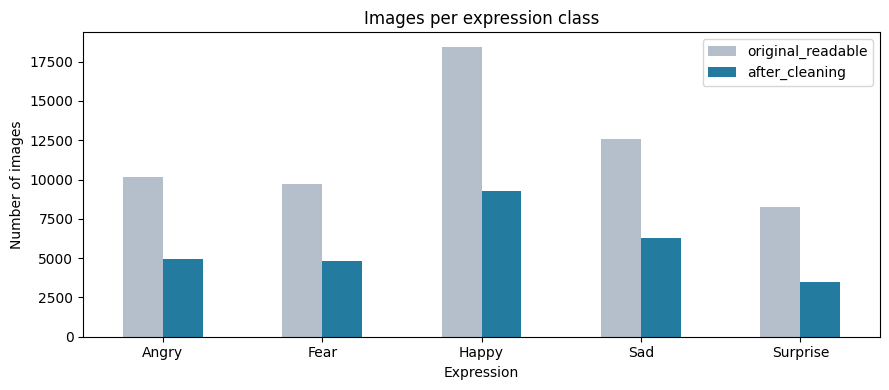

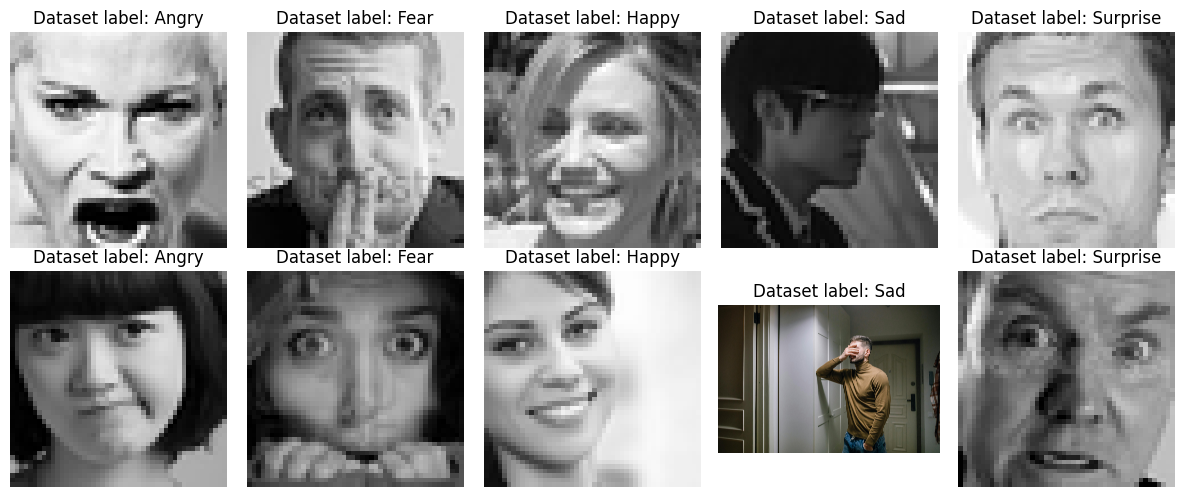

,image_size,width,height,image_count
0,48 x 48,48,48,57756
1,640 x 640,640,640,864
2,4000 x 6000,4000,6000,23
3,150 x 100,150,100,16
4,6000 x 4000,6000,4000,16
5,1600 x 1067,1600,1067,12
6,6720 x 4480,6720,4480,7
7,150 x 225,150,225,7
8,4480 x 6720,4480,6720,7
9,275 x 183,275,183,6


In [7]:
counts.plot(kind='bar', figsize=(9, 4), color=['#b5becb', '#247ba0'])
plt.title('Images per expression class')
plt.xlabel('Expression')
plt.ylabel('Number of images')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(RUN_DIR / 'class_distribution.png', dpi=150)
plt.show()

fig, axes = plt.subplots(2, len(CLASS_NAMES), figsize=(12, 5))
for column, label in enumerate(CLASS_NAMES):
    examples = clean[clean.label == label].sample(2, random_state=SEED)
    for row, (_, item) in enumerate(examples.iterrows()):
        with Image.open(DATA_DIR / item.path) as image:
            axes[row, column].imshow(ImageOps.exif_transpose(image).convert('RGB'))
        axes[row, column].set_title(f'Dataset label: {label}')
        axes[row, column].axis('off')
plt.tight_layout()
plt.show()
image_sizes = (
    manifest.groupby(['width', 'height'])
    .size()
    .reset_index(name='image_count')
    .sort_values('image_count', ascending=False)
    .head(10)
    .reset_index(drop=True)
)

image_sizes.insert(0, 'image_size', image_sizes['width'].astype(str) + ' x ' + image_sizes['height'].astype(str))
display(image_sizes)

### Dataset Splitting (70:15:15)

Dataset yang telah melalui proses cleaning dibagi menjadi tiga subset menggunakan `train_test_split()` dari Scikit-learn.

- **Training (70%)**: Digunakan untuk melatih CNN dan memperbarui bobot model melalui backpropagation.
- **Validation (15%)**: Digunakan untuk memantau performa model selama training serta memilih model terbaik.
- **Testing (15%)**: Digunakan untuk mengevaluasi performa akhir model terhadap data yang belum digunakan dalam training maupun pemilihan model.

Pembagian dilakukan dua tahap, yaitu memisahkan 70% training dan 30% data sementara, kemudian membagi data sementara menjadi dua bagian sama besar.

Parameter `stratify` mempertahankan proporsi setiap kelas ekspresi, sedangkan `random_state=SEED` memastikan pembagian data dapat direproduksi.

Selain itu, dilakukan pemeriksaan keunikan path dan hash piksel untuk memastikan tidak terdapat duplikat identik pada dataset hasil pembagian.

In [8]:
train_df, remaining_df = train_test_split(
    clean,
    test_size=0.30,
    stratify=clean.target,
    random_state=SEED
)

val_df, test_df = train_test_split(
    remaining_df,
    test_size=0.50,
    stratify=remaining_df.target,
    random_state=SEED
)

train_df, val_df, test_df = (
    frame.reset_index(drop=True)
    for frame in (train_df, val_df, test_df)
)

split_manifest = pd.concat([
    train_df.assign(split='train'),
    val_df.assign(split='validation'),
    test_df.assign(split='test')
], ignore_index=True)

assert split_manifest.path.is_unique
assert split_manifest.pixel_sha256.is_unique
assert len(split_manifest) == len(clean)
assert set(train_df.target) == set(val_df.target) == set(test_df.target) == set(range(len(CLASS_NAMES)))

split_manifest.to_csv(RUN_DIR / 'split_manifest.csv', index=False)

display(
    pd.crosstab(
        split_manifest.label,
        split_manifest.split
    ).reindex(CLASS_NAMES)[['train', 'validation', 'test']]
)

print('No exact decoded-pixel duplicates cross the splits.')

split,train,validation,test
label,,,
Angry,3471,744,744
Fear,3375,723,724
Happy,6478,1389,1388
Sad,4417,946,947
Surprise,2431,521,520


No exact decoded-pixel duplicates cross the splits.


## 7. Ubah gambar menjadi tensor dan buat DataLoader
Seluruh gambar diubah menjadi **grayscale 64 × 64**. Nilai piksel diubah dari 0–255 menjadi 0–1,
lalu dinormalisasi ke sekitar −1 sampai 1.

`RandomHorizontalFlip` memberi variasi gambar pada **train saja**. Validation dan test memakai transformasi tetap.
`Dataset` mengambil satu gambar dan label; `DataLoader` menggabungkannya menjadi batch.

In [9]:
base_steps = [
    transforms.Grayscale(num_output_channels=1),
    transforms.Resize(
        (IMAGE_SIZE, IMAGE_SIZE),
        interpolation=transforms.InterpolationMode.BILINEAR
    ),
]

if USE_AUGMENTATION:
    train_transform = transforms.Compose([
        *base_steps,
        transforms.RandomHorizontalFlip(p=0.5),
        transforms.RandomRotation(degrees=10),
        transforms.ColorJitter(
            brightness=0.10,
            contrast=0.10
        ),
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])
else:
    train_transform = transforms.Compose([
        *base_steps,
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

eval_transform = transforms.Compose([
    *base_steps,
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

class FaceDataset(Dataset):
    def __init__(self, frame, root, transform):
        self.frame = frame.reset_index(drop=True)
        self.root, self.transform = Path(root), transform

    def __len__(self):
        return len(self.frame)

    def __getitem__(self, index):
        item = self.frame.iloc[index]
        with Image.open(self.root / item.path) as image:
            image = ImageOps.exif_transpose(image).convert('RGB')
            tensor = self.transform(image)
        return tensor, int(item.target)

def seed_worker(worker_id):
    worker_seed = torch.initial_seed() % 2**32
    random.seed(worker_seed)
    np.random.seed(worker_seed)

from torch.utils.data import DataLoader, WeightedRandomSampler

def make_loaders():
    generator = torch.Generator().manual_seed(SEED)
    train_labels = train_df["target"].to_numpy()
    class_counts = np.bincount(train_labels,minlength=len(CLASS_NAMES))

    assert np.all(class_counts > 0), ("Every class must have at least one training sample.")

    sample_weights = 1.0 / class_counts[train_labels]
    sampler = WeightedRandomSampler(
        weights=torch.as_tensor(
            sample_weights, dtype=torch.double
        ),
        num_samples=len(sample_weights),
        replacement=True,
        generator=generator
    )

    options = dict(batch_size=BATCH_SIZE,num_workers=NUM_WORKERS,pin_memory=DEVICE.type == "cuda",worker_init_fn=seed_worker,drop_last=False)
    train_loader = DataLoader(FaceDataset(train_df, DATA_DIR, train_transform),sampler=sampler,generator=generator,**options)
    val_loader = DataLoader(FaceDataset(val_df, DATA_DIR, eval_transform),shuffle=False,**options)
    test_loader = DataLoader(FaceDataset(test_df, DATA_DIR, eval_transform),shuffle=False,**options)

    return train_loader, val_loader, test_loader

train_loader, val_loader, test_loader = make_loaders()
images, labels = next(iter(train_loader))

print('Image batch:', tuple(images.shape), '= (batch, channel, height, width)')
print('Label batch:', tuple(labels.shape))
print('Pixel range:', images.min().item(), images.max().item())

Image batch: (64, 1, 64, 64) = (batch, channel, height, width)
Label batch: (64,)
Pixel range: -1.0 1.0


## 8. Bangun CNN dari awal
**Conv2d:** mempelajari pola lokal pada gambar. **ReLU:** memberi kemampuan mempelajari hubungan nonlinier.
**MaxPool2d:** mengecilkan ukuran fitur. **Linear:** mengubah fitur menjadi lima skor kelas.
**Dropout:** menonaktifkan sebagian fitur secara acak saat latihan untuk membantu mengurangi overfitting.

Alur bentuk tensor: `1×64×64 → 32×32×32 → 64×16×16 → 128×8×8 → 128×4×4 → 5 skor`.
Keluaran berupa **logits** (skor mentah). Jangan menambahkan softmax sebelum `CrossEntropyLoss`;
softmax baru dipakai ketika menampilkan skor prediksi.

In [10]:
class ImprovedCNN(nn.Module):
    def __init__(self, num_classes=5):
        super().__init__()

        self.features = nn.Sequential(
            # Block 1
            nn.Conv2d(1, 32, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(32),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 2
            nn.Conv2d(32, 64, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
            nn.Dropout2d(0.10),

            # Block 3
            nn.Conv2d(64, 128, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(128),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),

            # Block 4
            nn.Conv2d(128, 256, kernel_size=3, padding=1, bias=False),
            nn.BatchNorm2d(256),
            nn.ReLU(inplace=True),
            nn.MaxPool2d(2),
        )

        self.classifier = nn.Sequential(
            nn.Flatten(),
            nn.Linear(256 * 4 * 4, 256),
            nn.ReLU(inplace=True),
            nn.Dropout(0.4),
            nn.Linear(256, num_classes)
        )

    def forward(self, x):
        x = self.features(x)
        return self.classifier(x)


model = ImprovedCNN(num_classes=5).to(DEVICE)

with torch.no_grad():
    sample_logits = model(images[:2].to(DEVICE))

assert sample_logits.shape == (2, 5)
print(model)
print("Output shape:", sample_logits.shape)
print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

ImprovedCNN(
  (features): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (4): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (5): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (6): ReLU(inplace=True)
    (7): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (8): Dropout2d(p=0.1, inplace=False)
    (9): Conv2d(64, 128, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
    (10): BatchNorm2d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (11): ReLU(inplace=True)
    (12): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (13): Conv2d(128, 256, kernel_size=(3, 3), strid

## 9. Loss, optimizer, dan fungsi satu epoch
**Loss** mengukur kesalahan model terhadap label. **Optimizer Adam** memperbarui bobot berdasarkan gradien.
Karena jumlah kelas tidak seimbang, bobot kelas dihitung **hanya dari data train**.
Set `USE_CLASS_WEIGHTS = False` untuk eksperimen pembanding di run terpisah.

Urutan latihan: `zero_grad → forward → loss → backward → optimizer.step`.
Saat evaluasi, `model.eval()` menonaktifkan dropout dan gradien tidak dihitung.
Macro-F1 menghitung F1 setiap kelas lalu merata-ratakannya, sehingga kelas yang lebih sedikit tetap diperhatikan.

In [11]:
train_counts = np.bincount(train_df.target.to_numpy(), minlength=len(CLASS_NAMES))
weights = len(train_df) / (len(CLASS_NAMES) * train_counts)
class_weights = torch.tensor(weights, dtype=torch.float32, device=DEVICE) if USE_CLASS_WEIGHTS else None
criterion = nn.CrossEntropyLoss()  # Change into unweighted loss function.
display(pd.DataFrame({'class': CLASS_NAMES, 'train_count': train_counts,
                      'loss_weight': weights if USE_CLASS_WEIGHTS else np.ones(len(CLASS_NAMES))}))

def run_epoch(model, loader, criterion, optimizer=None):
    training = optimizer is not None
    model.train(training)
    loss_sum, loss_denominator = 0.0, 0.0
    all_targets, all_predictions = [], []
    for images, targets in tqdm(loader, desc='Train' if training else 'Evaluate', leave=False):
        images = images.to(DEVICE, non_blocking=True)
        targets = targets.to(DEVICE, non_blocking=True)
        if training:
            optimizer.zero_grad(set_to_none=True)
        with torch.set_grad_enabled(training):
            logits = model(images)
            loss = criterion(logits, targets)
            if training:
                loss.backward()
                optimizer.step()
        # CrossEntropyLoss(weight=...) divides by the sum of the observed class weights.
        denominator = criterion.weight[targets].sum().item() if criterion.weight is not None else targets.numel()
        loss_sum += loss.item() * denominator
        loss_denominator += denominator
        all_targets.extend(targets.detach().cpu().tolist())
        all_predictions.extend(logits.detach().argmax(dim=1).cpu().tolist())
    metrics = {
        'loss': loss_sum / loss_denominator,
        'accuracy': accuracy_score(all_targets, all_predictions),
        'macro_f1': f1_score(all_targets, all_predictions, labels=list(range(len(CLASS_NAMES))),
                             average='macro', zero_division=0),
    }
    return metrics, np.asarray(all_targets), np.asarray(all_predictions)

,class,train_count,loss_weight
0,Angry,3471,1.162316
1,Fear,3375,1.195378
2,Happy,6478,0.622785
3,Sad,4417,0.913380
4,Surprise,2431,1.659564


## 10. Latih model dan simpan model terbaik
Sel ini memulai model baru dari awal, sehingga menjalankannya ulang tidak diam-diam melanjutkan bobot lama.
Setiap epoch menghasilkan metrik train dan validation. Bobot terbaik disimpan berdasarkan **validation macro-F1**.
Jika nilai tersebut tidak membaik selama `PATIENCE` epoch, latihan berhenti lebih awal.

`best_model.pt` dan `history.csv` disimpan setiap ada perkembangan, tetapi notebook ini tidak menyediakan
resume otomatis setelah sesi Colab terputus. Kamu tetap bisa memuat bobot terbaik untuk inferensi.
Jangan menilai keberhasilan hanya dari akurasi train yang tinggi.

In [12]:
import os

resume_path = RUN_DIR / "last_checkpoint.pt"
checkpoint_path = RUN_DIR / "best_model.pt"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

train_loader, val_loader, test_loader = make_loaders()

model = ImprovedCNN(len(CLASS_NAMES)).to(DEVICE)

# AdamW optimizer
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=1e-4
)

# Learning-rate scheduler
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="max",
    factor=0.5,
    patience=3,
    min_lr=1e-6
)

start_epoch = 1
best_val_f1 = -1.0
best_epoch = 0
stale_epochs = 0
history = []

if resume_path.exists():
    print("Checkpoint ditemukan. Memulihkan training...")

    checkpoint = torch.load(
        resume_path,
        map_location=DEVICE,
        weights_only=True
    )

    assert checkpoint["archive_sha256"] == config["archive_sha256"]
    assert checkpoint["class_names"] == CLASS_NAMES
    assert checkpoint["image_size"] == IMAGE_SIZE
    assert checkpoint["batch_size"] == BATCH_SIZE

    model.load_state_dict(checkpoint["model_state_dict"])
    optimizer.load_state_dict(checkpoint["optimizer_state_dict"])

    # Restore scheduler state if this checkpoint has one
    if "scheduler_state_dict" in checkpoint:
        scheduler.load_state_dict(checkpoint["scheduler_state_dict"])

    start_epoch = checkpoint["epoch"] + 1
    best_val_f1 = checkpoint["best_val_f1"]
    best_epoch = checkpoint["best_epoch"]
    stale_epochs = checkpoint["stale_epochs"]
    history = checkpoint["history"]

    random.setstate(checkpoint["python_rng_state"])

    np_state = checkpoint["numpy_rng_state"]
    np.random.set_state((
        np_state[0],
        np.array(np_state[1], dtype=np.uint32),
        np_state[2],
        np_state[3],
        np_state[4]
    ))

    torch.set_rng_state(checkpoint["torch_rng_state"].cpu())

    if DEVICE.type == "cuda" and "cuda_rng_state" in checkpoint:
        torch.cuda.set_rng_state_all(
            [state.cpu() for state in checkpoint["cuda_rng_state"]]
        )

    train_loader.generator.set_state(
        checkpoint["loader_rng_state"].cpu()
    )

    print(f"Training akan dilanjutkan dari epoch {start_epoch}")

else:
    print("Belum ada checkpoint. Training dimulai dari epoch 1.")

if stale_epochs >= PATIENCE:
    print("Training sebelumnya sudah memenuhi early stopping.")

else:
    for epoch in range(start_epoch, EPOCHS + 1):

        started = time.perf_counter()

        train_metrics, _, _ = run_epoch(
            model, train_loader, criterion, optimizer
        )

        val_metrics, _, _ = run_epoch(
            model, val_loader, criterion
        )

        # Update learning rate using validation macro-F1
        scheduler.step(val_metrics["macro_f1"])

        current_lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            **{f"train_{k}": v for k, v in train_metrics.items()},
            **{f"val_{k}": v for k, v in val_metrics.items()},
            "learning_rate": current_lr,
            "seconds": time.perf_counter() - started
        })

        print(
            f"Epoch {epoch}/{EPOCHS} | "
            f"train loss {train_metrics['loss']:.4f} | "
            f"val loss {val_metrics['loss']:.4f} | "
            f"val accuracy {val_metrics['accuracy']:.4f} | "
            f"val macro-F1 {val_metrics['macro_f1']:.4f} | "
            f"lr {current_lr:.2e}"
        )

        if val_metrics["macro_f1"] > best_val_f1:

            best_val_f1 = val_metrics["macro_f1"]
            best_epoch = epoch
            stale_epochs = 0

            torch.save({
                "model_state_dict": {
                    k: v.detach().cpu()
                    for k, v in model.state_dict().items()
                },
                "class_names": CLASS_NAMES,
                "image_size": IMAGE_SIZE,
                "best_epoch": best_epoch,
                "validation_macro_f1": float(best_val_f1),
                "config": config
            }, checkpoint_path)

            print("Saved new best model.")

        else:
            stale_epochs += 1

        np_state = np.random.get_state()

        latest_checkpoint = {
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "scheduler_state_dict": scheduler.state_dict(),
            "best_val_f1": best_val_f1,
            "best_epoch": best_epoch,
            "stale_epochs": stale_epochs,
            "history": history,
            "archive_sha256": config["archive_sha256"],
            "class_names": CLASS_NAMES,
            "image_size": IMAGE_SIZE,
            "batch_size": BATCH_SIZE,
            "python_rng_state": random.getstate(),
            "numpy_rng_state": (
                np_state[0],
                np_state[1].tolist(),
                np_state[2],
                np_state[3],
                np_state[4]
            ),
            "torch_rng_state": torch.get_rng_state(),
            "loader_rng_state": train_loader.generator.get_state()
        }

        if DEVICE.type == "cuda":
            latest_checkpoint["cuda_rng_state"] = (
                torch.cuda.get_rng_state_all()
            )

        temp_path = RUN_DIR / "last_checkpoint.tmp"
        torch.save(latest_checkpoint, temp_path)
        os.replace(temp_path, resume_path)

        pd.DataFrame(history).to_csv(
            RUN_DIR / "history.csv", index=False
        )

        print(f"Checkpoint epoch {epoch} berhasil disimpan.")

        if stale_epochs >= PATIENCE:
            print("Early stopping: validation macro-F1 did not improve.")
            break

print(
    f"Best epoch: {best_epoch}; "
    f"validation macro-F1: {best_val_f1:.4f}"
)

Checkpoint ditemukan. Memulihkan training...
Training akan dilanjutkan dari epoch 30
Training sebelumnya sudah memenuhi early stopping.
Best epoch: 24; validation macro-F1: 0.6233


In [13]:
resume_path = RUN_DIR / "last_checkpoint.pt"

print("Checkpoint ditemukan:", resume_path.exists())

if resume_path.exists():
    saved = torch.load(
        resume_path,
        map_location="cpu",
        weights_only=True
    )

    print("Epoch terakhir:", saved["epoch"])
    print("Best epoch:", saved["best_epoch"])
    print("Best validation F1:", saved["best_val_f1"])
    print("Stale epochs:", saved["stale_epochs"])

Checkpoint ditemukan: True
Epoch terakhir: 29
Best epoch: 24
Best validation F1: 0.6233133085963968
Stale epochs: 5


In [14]:
best_checkpoint = torch.load(
    RUN_DIR / "best_model.pt",
    map_location=DEVICE,
    weights_only=True
)

model.load_state_dict(best_checkpoint["model_state_dict"])
model.eval()

test_metrics, y_true, y_pred = run_epoch(
    model,
    test_loader,
    criterion
)

print(f"Test Accuracy: {test_metrics['accuracy'] * 100:.2f}%")
print(f"Test Macro F1: {test_metrics['macro_f1'] * 100:.2f}%")
print(f"Test Loss: {test_metrics['loss']:.4f}")

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

Test Accuracy: 65.23%
Test Macro F1: 61.61%
Test Loss: 0.9057


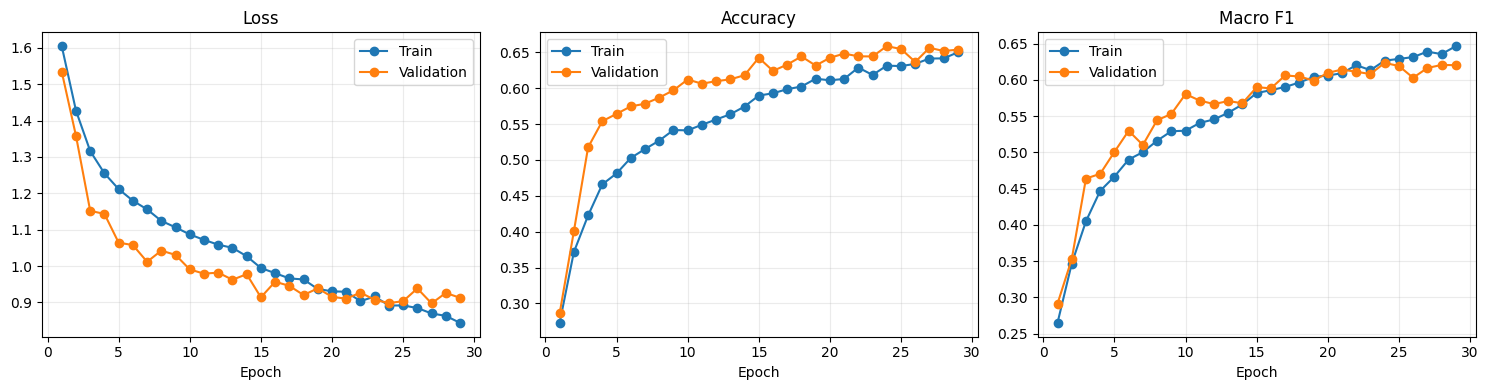

,epoch,train_loss,train_accuracy,train_macro_f1,val_loss,val_accuracy,val_macro_f1,learning_rate,seconds
0,1,1.604752,0.272804,0.264780,1.534288,0.285913,0.291261,0.00100,255.885507
1,2,1.427486,0.371505,0.346503,1.358119,0.400416,0.352652,0.00100,275.673579
2,3,1.316247,0.422516,0.404912,1.151886,0.517465,0.463829,0.00100,270.718419
3,4,1.255059,0.465943,0.446864,1.143509,0.554013,0.470344,0.00100,271.397229
4,5,1.211631,0.481162,0.466498,1.064302,0.564192,0.500496,0.00100,272.350341
5,6,1.179763,0.502727,0.490024,1.057835,0.574601,0.529694,0.00100,270.478364
6,7,1.155945,0.515120,0.500205,1.011800,0.578302,0.510126,0.00100,270.187998
7,8,1.124322,0.526869,0.515987,1.042517,0.586861,0.544289,0.00100,275.823247
8,9,1.106460,0.541642,0.529099,1.030727,0.597039,0.552869,0.00100,276.000310
9,10,1.087073,0.541196,0.529783,0.990758,0.612075,0.580282,0.00100,265.998576


In [15]:
history_df = pd.read_csv(RUN_DIR / 'history.csv')
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for axis, metric in zip(axes, ['loss', 'accuracy', 'macro_f1']):
    axis.plot(history_df.epoch, history_df[f'train_{metric}'], marker='o', label='Train')
    axis.plot(history_df.epoch, history_df[f'val_{metric}'], marker='o', label='Validation')
    axis.set(title=metric.replace('_', ' ').title(), xlabel='Epoch')
    axis.legend()
    axis.grid(alpha=0.25)
plt.tight_layout()
plt.savefig(RUN_DIR / 'training_curves.png', dpi=150)
plt.show()
display(history_df)

Evaluate:   0%|          | 0/68 [00:00<?, ?it/s]

{
  "loss": 0.9056665886614903,
  "accuracy": 0.6523247744621791,
  "macro_f1": 0.6161191478690593,
  "best_epoch": 24,
  "best_validation_macro_f1": 0.6233133085963968,
  "test_samples": 4323
}


,precision,recall,f1-score,support
Angry,0.592179,0.569892,0.580822,744.000000
Fear,0.452116,0.280387,0.346121,724.000000
Happy,0.869499,0.825648,0.847007,1388.000000
Sad,0.518460,0.696938,0.594595,947.000000
Surprise,0.682540,0.744231,0.712052,520.000000
accuracy,0.652325,0.652325,0.652325,0.652325
macro avg,0.622959,0.623419,0.616119,4323.000000
weighted avg,0.652482,0.652325,0.645782,4323.000000


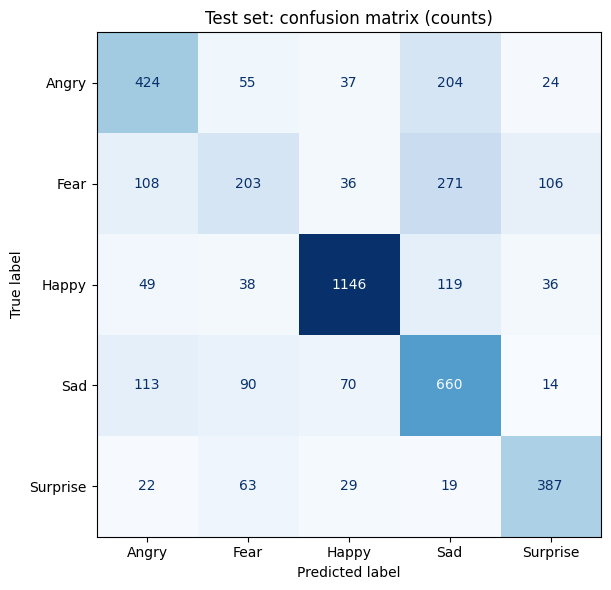

In [16]:
checkpoint = torch.load(checkpoint_path, map_location=DEVICE, weights_only=True)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
test_metrics, y_true, y_pred = run_epoch(model, test_loader, criterion)
class_ids = list(range(len(CLASS_NAMES)))
report = classification_report(y_true, y_pred, labels=class_ids, target_names=CLASS_NAMES,
                               output_dict=True, zero_division=0)
report_df = pd.DataFrame(report).transpose()
report_df.to_csv(RUN_DIR / 'classification_report.csv')
test_results = {**test_metrics, 'best_epoch': checkpoint['best_epoch'],
                'best_validation_macro_f1': checkpoint['validation_macro_f1'], 'test_samples': len(test_df)}
(RUN_DIR / 'test_metrics.json').write_text(json.dumps(test_results, indent=2))
print(json.dumps(test_results, indent=2))
display(report_df)

predictions = test_df[['path', 'label', 'target']].copy()
predictions['predicted_index'] = y_pred
predictions['predicted_label'] = [CLASS_NAMES[index] for index in y_pred]
predictions.to_csv(RUN_DIR / 'test_predictions.csv', index=False)
cm = confusion_matrix(y_true, y_pred, labels=class_ids)
pd.DataFrame(cm, index=CLASS_NAMES, columns=CLASS_NAMES).to_csv(RUN_DIR / 'confusion_matrix.csv')
fig, ax = plt.subplots(figsize=(7, 6))
ConfusionMatrixDisplay(cm, display_labels=CLASS_NAMES).plot(ax=ax, cmap='Blues', colorbar=False)
ax.set_title('Test set: confusion matrix (counts)')
plt.tight_layout()
plt.savefig(RUN_DIR / 'confusion_matrix.png', dpi=150)
plt.show()

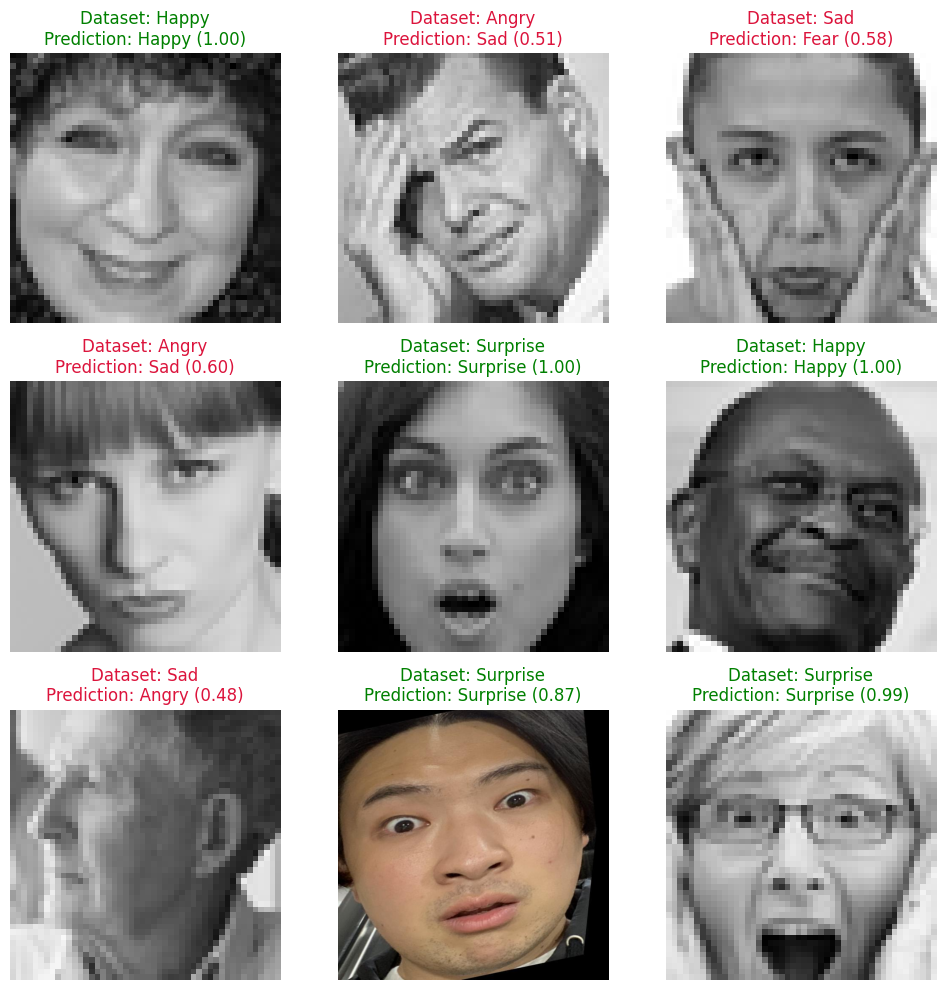

In [20]:
@torch.inference_mode()
def predict_image(path):
    model.eval()
    with Image.open(path) as image:
        rgb = ImageOps.exif_transpose(image).convert('RGB')
        tensor = eval_transform(rgb).unsqueeze(0).to(DEVICE)
    scores = torch.softmax(model(tensor), dim=1).squeeze(0).cpu().numpy()
    return CLASS_NAMES[int(scores.argmax())], {name: float(score) for name, score in zip(CLASS_NAMES, scores)}

examples = val_df.sample(n=min(9, len(val_df)), random_state=SEED)
fig, axes = plt.subplots(3, 3, figsize=(10, 10))
for axis in axes.flat:
    axis.axis('off')
for axis, (_, item) in zip(axes.flat, examples.iterrows()):
    path = DATA_DIR / item.path
    predicted_label, scores = predict_image(path)
    with Image.open(path) as image:
        axis.imshow(ImageOps.exif_transpose(image).convert('RGB'))
    axis.set_title(f'Dataset: {item.label}\nPrediction: {predicted_label} ({scores[predicted_label]:.2f})',
                   color='green' if predicted_label == item.label else 'crimson')
plt.tight_layout()
plt.savefig(RUN_DIR / 'validation_sample_predictions.png', dpi=150)
plt.show()


In [18]:
experiment_log = pd.DataFrame([{
    'run': RUN_DIR.name, 'seed': SEED, 'image_size': IMAGE_SIZE, 'batch_size': BATCH_SIZE,
    'learning_rate': LEARNING_RATE, 'epochs_completed': len(history), 'best_epoch': checkpoint['best_epoch'],
    'augmentation': USE_AUGMENTATION, 'class_weights': USE_CLASS_WEIGHTS,
    'validation_macro_f1': checkpoint['validation_macro_f1'],
    'test_accuracy': test_metrics['accuracy'], 'test_macro_f1': test_metrics['macro_f1'],
    'notes': 'First CNN baseline; add your observations here.'
}])
experiment_log.to_csv(RUN_DIR / 'experiment_log.csv', index=False)
display(experiment_log)
print('Saved outputs:')
for path in sorted(RUN_DIR.iterdir()):
    print(f'  {path.name} ({path.stat().st_size / 1024:.1f} KB)')
print('Persistent Google Drive folder:', RUN_DIR)

,run,seed,image_size,batch_size,learning_rate,epochs_completed,best_epoch,augmentation,class_weights,validation_macro_f1,test_accuracy,test_macro_f1,notes
0,cnn_experiment_v3,42,64,64,0.0003,29,24,True,True,0.623313,0.652325,0.616119,First CNN baseline; add your observations here.


Saved outputs:
  audit_manifest.csv (5926.9 KB)
  audit_summary.json (0.2 KB)
  best_model.pt (5632.0 KB)
  class_distribution.png (42.9 KB)
  classification_report.csv (0.6 KB)
  clean_manifest.csv (2941.6 KB)
  config.json (0.6 KB)
  conflicting_labels.csv (26.5 KB)
  confusion_matrix.csv (0.1 KB)
  confusion_matrix.png (53.5 KB)
  environment_versions.json (0.2 KB)
  experiment_log.csv (0.3 KB)
  history.csv (4.1 KB)
  invalid_images.csv (0.0 KB)
  last_checkpoint.pt (16908.5 KB)
  sample_predictions.png (704.5 KB)
  split_manifest.csv (3127.3 KB)
  test_metrics.json (0.2 KB)
  test_predictions.csv (141.1 KB)
  training_curves.png (118.5 KB)
Persistent Google Drive folder: /content/drive/MyDrive/fer_cnn_outputs/cnn_experiment_v3


In [19]:
DOWNLOAD_RESULTS = True  # Change to True if you want a download.
if DOWNLOAD_RESULTS:
    from google.colab import files
    results_zip = shutil.make_archive(f'/content/{RUN_DIR.name}_results', 'zip', root_dir=RUN_DIR)
    files.download(results_zip)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>